In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [1]:
import os
BRANCH = "nandini"

!pip install -q --no-deps tf-keras

from kaggle_secrets import UserSecretsClient
tok = UserSecretsClient().get_secret("github_token")
repo = "/tmp/ocular-adv-xai"
url = f"https://{tok}@github.com/nandininautiyal/ocular-adv-xai.git"
if not os.path.exists(repo):
    !git clone -q -b {BRANCH} {url} {repo}
    !git -C {repo} remote set-url origin https://github.com/nandininautiyal/ocular-adv-xai.git
else:
    !git -C {repo} pull {url} {BRANCH}
%cd {repo}
!git branch --show-current
!git log -1 --oneline

!python scripts/01_build_manifest.py --out /kaggle/working/manifest_raw.csv
!python scripts/02_make_splits.py

/tmp/ocular-adv-xai
nandini
7bed0c0 (HEAD -> nandini, origin/nandini) Margin-loss option for white-box attacks, uniform CW signature, (row, col) patch positions, NaN Spearman; add attack validation scripts
Data root: /kaggle/input/datasets/mubashirulhassan00/visob-augmented-recent/VISOB_Augmented_Recent
Wrote 134258 rows to /kaggle/working/manifest_raw.csv
Skipped 0 files that did not match the filename pattern
classes: 300 | images: 69341

images per split:
 split
train         41607
test          13868
validation    13866

images per class per split (min / median / max):
split  test  train  validation
min     4.0   12.0         4.0
50%    48.0  144.0        48.0
max    75.0  226.0        75.0

fraction of test images whose (subject, condition, eye, phase) bucket also has training images: 98.2%
tree written to: /tmp/ocular_recognition
manifest written to: /kaggle/working/manifest_split.csv


In [2]:
CKPT = "/kaggle/input/datasets/nandininautiyal/ocular-xception-arcface-full-baseline/trained_models/Xception_ArcFace_full.keras"
!python scripts/04_eval_clean.py --split-dir /tmp/ocular_recognition --n-classes 300 --ckpt "{CKPT}" --manifest /kaggle/working/manifest_split.csv --tag full

TF 2.20.0 | tf.keras comes from: tf_keras.src.engine.training | GPUs: 2
I0000 00:00:1791950734.977964     168 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1791950734.982322     168 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5
loaded: /kaggle/input/datasets/nandininautiyal/ocular-xception-arcface-full-baseline/trained_models/Xception_ArcFace_full.keras
Found 13868 images belonging to 300 classes.
  batch 20/217
  batch 40/217
  batch 60/217
  batch 80/217
  batch 100/217
  batch 120/217
  batch 140/217
  batch 160/217
  batch 180/217
  batch 200/217
  batch 217/217
subject in manifest == subject in folder name: True

images evaluated: 13868
CLEAN test accuracy, margin-free: 0.9796  (approx. 95% CI 0.9772

saved /kaggle/working/patch_positions.png


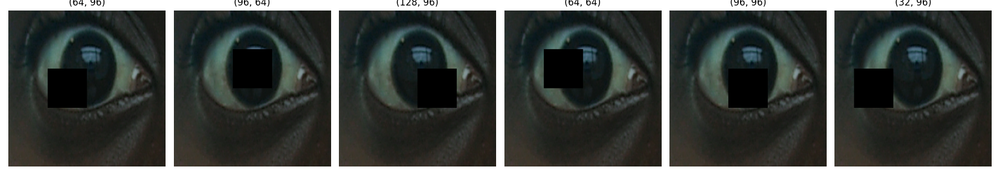

In [4]:
import pandas as pd
from IPython.display import Image, display
p = pd.read_csv("/kaggle/working/eval_clean/correct_test_full.csv").link_path.iloc[0]
!python scripts/07_check_patch_positions.py "{p}"
display(Image("/kaggle/working/patch_positions.png"))

In [5]:
!python scripts/08_check_attacks.py --ckpt "{CKPT}" --n 100

I0000 00:00:1791951169.621760    1586 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1791951169.624605    1586 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5
100 correctly classified test images

[1] margin-free logits vs model([image, zeros])
    argmax agreement: 1.0
    max |softmax(logits) - model output|: 2.276897430419922e-05
    clean accuracy on this sample (should be 1.0): 1.0
    top-1 minus top-2 logit gap: median 53.1 | 10th pct 49.2 | 90th pct 53.9

[2] vendored reference attacks, eps = 0.001
{'family': 'paper', 'attack': 'fgsm', 'loss': 'reference', 'eps': 0.001, 'ASR': 0.37, 'mean_linf': 0.0010000019101426005, 'max_linf': 0.0010000020265579224, 'secs_per_image': 0.28691395282745363}
{'family'

In [9]:
from kaggle_secrets import UserSecretsClient
tok = UserSecretsClient().get_secret("github_token")
url = f"https://{tok}@github.com/nandininautiyal/ocular-adv-xai.git"
%cd /tmp/ocular-adv-xai
!git branch --show-current
!git pull {url} nandini
!git log -1 --oneline
!ls scripts

/tmp/ocular-adv-xai
nandini
remote: Enumerating objects: 6, done.
remote: Counting objects: 100% (6/6), done.
remote: Compressing objects: 100% (2/2), done.
remote: Total 4 (delta 2), reused 4 (delta 2), pack-reused 0 (from 0)
Unpacking objects: 100% (4/4), 2.71 KiB | 2.71 MiB/s, done.
From https://github.com/nandininautiyal/ocular-adv-xai
 * branch            nandini    -> FETCH_HEAD
Updating 7bed0c0..ac114bb
Fast-forward
 scripts/09_heatmap_demo.py | 136 +++++++++++++++++++++++++++++++++++++++++++++
 1 file changed, 136 insertions(+)
 create mode 100644 scripts/09_heatmap_demo.py
ac114bb (HEAD -> nandini) heatmap demo script
00_sanity_check.py    04_eval_clean.py		   08_check_attacks.py
01_build_manifest.py  05_run_experiment.py	   09_heatmap_demo.py
02_make_splits.py     06_attack_smoke.py
03_train_baseline.py  07_check_patch_positions.py


In [10]:
!python scripts/09_heatmap_demo.py --ckpt "{CKPT}" --n 6 --attack pgd --eps 0.00784 --out-dir /kaggle/working/demo_pgd

I0000 00:00:1791952468.441836    1763 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1791952468.444660    1763 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5
pgd eps=0.00784 {'loss': 'margin'} | max L-inf actually used: 0.00784

accuracy on the true class per stage:
  clean                  1.00
  attacked               0.00
  attacked+jpeg          0.17
  attacked+bit4          0.50
  noise (control)        1.00
  clean+jpeg (control)   1.00

native map shape: (6, 8, 8)

clean vs stage (mean over images; spearman and top-k: 1 = same, js: 0 = same)
     cam                stage  spearman  top10_intersection  top25_intersection    js  cosine
layercam             attacked     0.663               0.361        

In [11]:
   !python scripts/09_heatmap_demo.py --ckpt "{CKPT}" --n 6 --attack pgd --eps 0.00784 --out-dir /kaggle/working/demo_pgd
   !python scripts/09_heatmap_demo.py --ckpt "{CKPT}" --n 12 --attack fgsm --eps 0.00392 --out-dir /kaggle/working/demo_fgs

I0000 00:00:1791952521.804761    1876 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1791952521.808210    1876 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5
pgd eps=0.00784 {'loss': 'margin'} | max L-inf actually used: 0.00784

accuracy on the true class per stage:
  clean                  1.00
  attacked               0.00
  attacked+jpeg          0.17
  attacked+bit4          0.50
  noise (control)        1.00
  clean+jpeg (control)   1.00

native map shape: (6, 8, 8)

clean vs stage (mean over images; spearman and top-k: 1 = same, js: 0 = same)
     cam                stage  spearman  top10_intersection  top25_intersection    js  cosine
layercam             attacked     0.663               0.361        

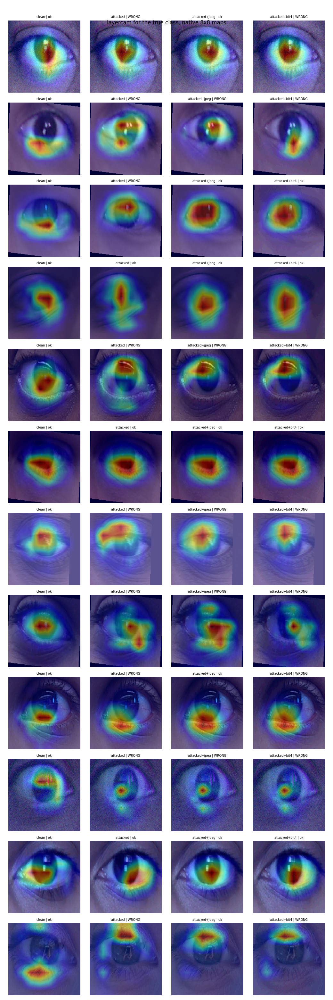

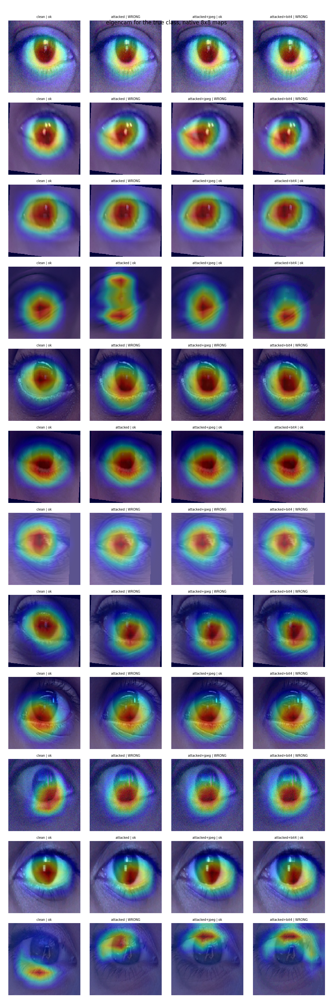

In [13]:
from IPython.display import Image, display
display(Image("/kaggle/working/demo_fgs/demo_layercam.png"))
display(Image("/kaggle/working/demo_fgs/demo_eigencam.png"))

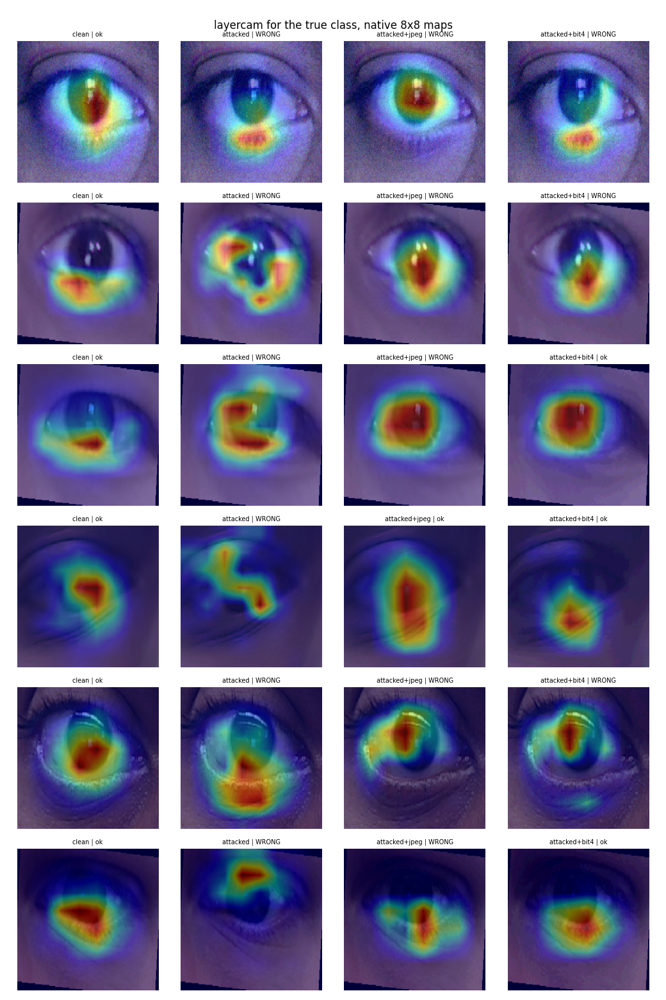

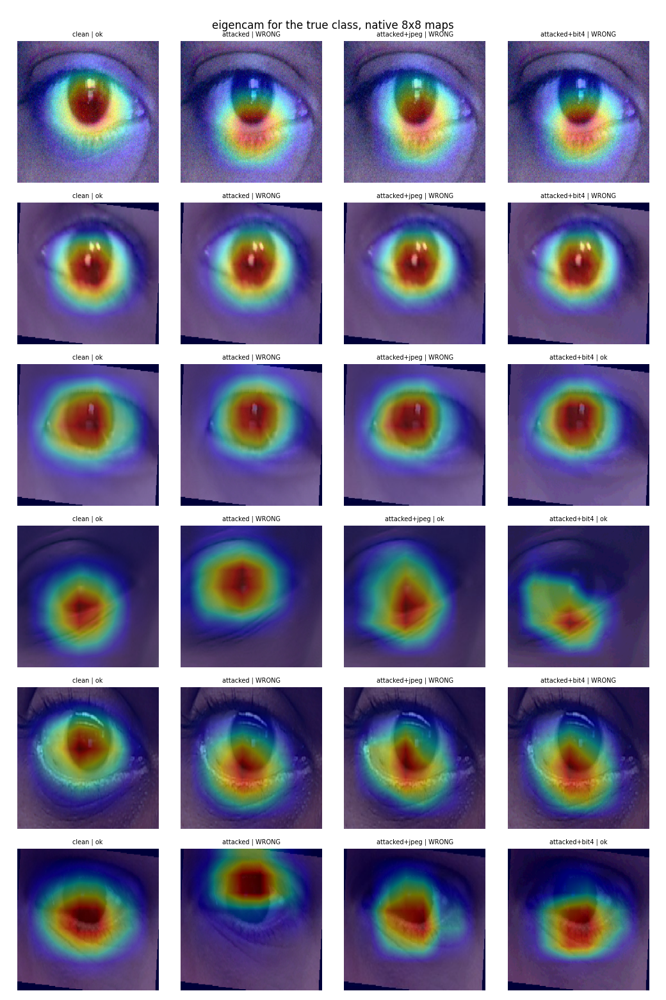

In [14]:
display(Image("/kaggle/working/demo_pgd/demo_layercam.png"))
display(Image("/kaggle/working/demo_pgd/demo_eigencam.png"))